# Lab 9

Author: Khanh Do

In [2]:
## Standard Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import math

## Question 1

In [3]:
## Squared Error Cost for Linear Regression
def cost_function(X, y, w):
    n = len(y)
    pred_y = np.dot(X,w)
    err = y - pred_y
    cost = (1./n)*np.dot(np.transpose(err),err)                 
    return cost 

## Simulated Data for Question 1
np.random.seed(0)
x = np.linspace(-10, 10, 100)
y = 3 * x + np.random.normal(0, 3, 100)

### Part A

If a simple linear regression model with a single predictor and no intercept is used then: 
- The dimension of **X** is $n \times 1$
- The dimension of **y** is $n \times 1$
- The dimension of $\hat{w}$ if $1 \times 1$.

### Part B

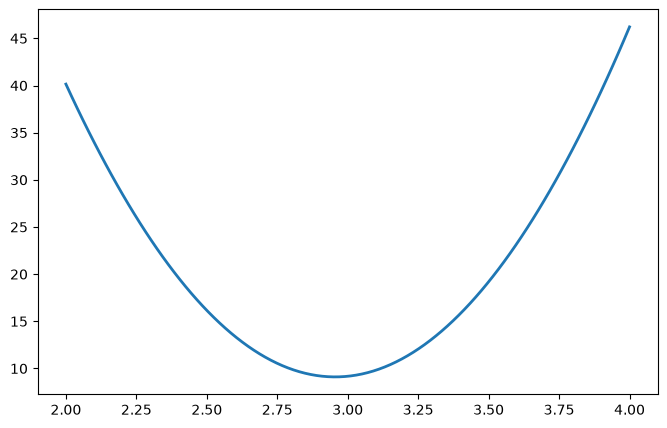

In [7]:
def cost_function_modified(X, y, w):
    n = len(y)
    pred_y = X * w
    err = y - pred_y
    cost = (1./n)*np.dot(np.transpose(err),err)                 
    return cost 

w1s = np.linspace(2, 4, 100)
costs = []
for w1 in w1s:
    costs.append(cost_function_modified(x, y, w1))
    
plt.figure(figsize=(8, 5))
plt.plot(w1s, costs, linewidth=2)

### Part C

The sign of the gradient value should be negative because at $\hat{w_1} = 2$, the tangent line is downward. To improve the cost, we should increase $\hat{w_1}$.

### Part D

The magnitude of the gradient value should be smaller because on the graph, the tangent at $\hat{w_1}=2.7$ is flatter because it is closer to the bottom of the parabola.

### Part E

The irreducible error here would be the random noise added to $3x$. Even if we use the true slope of $3$, we still cannot recover the true observed values due to the noise. Thus it is irreducible. We can see from the graph the bottom of the parabola shows the lowest MSE for that simulated sample.

## Question 2

In [8]:
## Define gradient descent function for linear regression
def grad_descent(X, y, w, alpha, n_iter):
    costs = np.zeros(n_iter)
    n = len(y) 
    
    for i in range(n_iter):
        pred_y = np.dot(X,w)
        grad = (-2./n)*np.dot(np.transpose(X), (y - pred_y))
        w = w - alpha*grad
        costs[i] = cost_function(X, y, w)
        
    return w, costs

### Part A

$z = y - \hat{y}$

$\hat{y} = e^{\hat{w_1}x}$

$\dfrac{d\text{cost}}{d\hat{w_1}} = \dfrac{2}{n} \times -I \times x\hat{y} = \dfrac{-2}{n}z^T\hat{y}x = \dfrac{-2}{n}(y - \hat{y})^T\hat{y}x = \dfrac{-2}{n}(y - e^{\hat{w_1}x})^Te^{\hat{w_1}x}x$

In [10]:
def cost_function_2a(x, y, w):
    n = len(y)
    pred_y = np.exp(w*x)
    err = y - pred_y
    cost = (1./n)*np.dot(np.transpose(err),err)                 
    return cost 

In [11]:
def grad_descent_2a(x, y, w):
    n = len(y)
    pred_y = np.exp(w*x)
    err = y - pred_y
    return (-2./n)*np.dot(np.transpose(err), pred_y * x)
    

### Part B

In [14]:
## Define gradient descent function for linear regression
def grad_descent_modified(X, y, w, alpha, n_iter):
    costs = np.zeros(n_iter)
    n = len(y) 
    
    for i in range(n_iter):
        grad = grad_descent_2a(X, y, w)
        w = w - alpha*grad
        costs[i] = cost_function_2a(X, y, w)
        
    return w, costs

### Part C

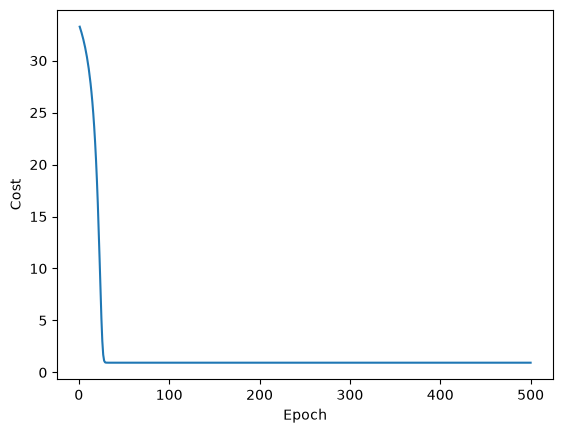

-2.03708742374837


In [20]:
## Simulated Data for Question 2
np.random.seed(0)
x = np.linspace(-1.5, 1.5, 100)
y = np.exp(-2 * x) + np.random.normal(0, 1, 100)

w_hat, gdres = grad_descent_modified(x, y, w=0.0, alpha=0.005, n_iter=500)

epochs = np.arange(1, len(gdres) + 1)
plt.plot(epochs, gdres)
plt.xlabel("Epoch")
plt.ylabel("Cost")
plt.show()

print(w_hat)

### Part D

Comparing with the true value of $-2$, our final estimate of $w_1$ being around $-2.037$ is very close. Since it's such a small difference potentially explained by noise, I would say the gradient descent effectively estimated this parameter.

## Question 3

### Part A

### Part B

### Part C